# Local Outlier Factor (LOF)

"Far from everything" is the wrong test when clusters have **different densities**. A point 1 unit from a razor-tight cluster is clearly out of place; a point 1 unit from its neighbours in a sparse cluster is perfectly normal. LOF asks instead: **is this point sparser than the points around it?**

## How it works

For a point `p` and `k = n_neighbors`:

1. **k-distance(p)** — distance to `p`'s `k`-th nearest neighbour.
2. **Reachability distance** `reach(p, o) = max(k-distance(o), dist(p, o))` — distances are floored by the neighbour's own scale, which smooths out noise.
3. **Local reachability density** `lrd(p) = 1 / mean reach(p, o)` over `p`'s `k` neighbours.
4. **`LOF(p) = mean(lrd(o) for neighbours o) / lrd(p)`**

| LOF | Meaning |
|---|---|
| ≈ 1 | as dense as its neighbours — inlier |
| ≫ 1 | much sparser than its neighbours — outlier |

The sign follows scikit-learn: `negative_outlier_factor_ = −LOF`, and `contamination` sets the fraction flagged (`−1`) by taking that percentile of the training scores. The tests show a point that a plain "distance to the k-th neighbour" rule ranks as unremarkable while LOF puts it first, and the demo matches scikit-learn exactly for both training and new points.

`k` is the one knob: small is noisy, large smooths over small clusters of anomalies (a group of outliers bigger than `k` look like a normal cluster to each other).

Compare `39_isolation_forest`: that one needs no distances and scales better, but LOF is better when density varies across the data.

`ponytail:` brute-force `O(n²)` distance matrix; use a KD-/ball-tree for large `n`.

## Usage

```python
# (the class is defined in the Implementation section below)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
labels = lof.fit_predict(X)            # -1 outlier, 1 inlier (training points)
lof.negative_outlier_factor_           # -LOF per training point
lof.predict(X_new)                     # new points, scored against the training set
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _dists(A, B):
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.sqrt(np.maximum(d2, 0.0))


class LocalOutlierFactor:
    """Anomaly detection by comparing a point's LOCAL density with its neighbours' densities.

    "Far from everything" is the wrong test when clusters have different densities: a point 1 unit
    from a very tight cluster is a clear outlier, while 1 unit between points of a sparse cluster is
    normal. LOF asks "is this point sparser than the points around it?":

    1. k-distance(p): distance to p's k-th nearest neighbour.
    2. reach-dist(p, o) = max(k-distance(o), dist(p, o)) -- distances are floored by the neighbour's own scale.
    3. lrd(p) = 1 / mean reach-dist from p to its k neighbours   (local reachability density).
    4. LOF(p) = mean(lrd(neighbours)) / lrd(p).

    LOF ~ 1: as dense as its neighbours (inlier). LOF >> 1: much sparser than its neighbours (outlier).
    Scores and sign convention follow scikit-learn: `negative_outlier_factor_` = -LOF.

    ponytail: brute-force O(n^2) distance matrix; use a KD-tree / ball-tree for large n."""

    def __init__(self, n_neighbors=20, contamination=0.1):
        self.n_neighbors = n_neighbors
        self.contamination = contamination

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        k = self.n_neighbors
        D = _dists(X, X)
        np.fill_diagonal(D, np.inf)                       # a point is not its own neighbour
        self.neighbors_ = np.argsort(D, axis=1)[:, :k]
        nd = np.take_along_axis(D, self.neighbors_, axis=1)
        self.k_distance_ = nd[:, -1]
        reach = np.maximum(nd, self.k_distance_[self.neighbors_])
        self.lrd_ = 1.0 / np.maximum(reach.mean(axis=1), 1e-10)
        lof = self.lrd_[self.neighbors_].mean(axis=1) / self.lrd_
        self.negative_outlier_factor_ = -lof
        self.offset_ = np.quantile(-lof, self.contamination)  # below this -> outlier
        self.X_fit_ = X
        return self

    def score_samples(self, X):
        """-LOF of NEW points w.r.t. the training set (higher = more normal, ~ -1 for inliers)."""
        X = np.asarray(X, dtype=float)
        D = _dists(X, self.X_fit_)
        nbrs = np.argsort(D, axis=1)[:, : self.n_neighbors]
        nd = np.take_along_axis(D, nbrs, axis=1)
        reach = np.maximum(nd, self.k_distance_[nbrs])
        lrd = 1.0 / np.maximum(reach.mean(axis=1), 1e-10)
        return -(self.lrd_[nbrs].mean(axis=1) / lrd)

    def predict(self, X):
        """-1 outlier, 1 inlier, for new points."""
        return np.where(self.score_samples(X) < self.offset_, -1, 1)

    def fit_predict(self, X):
        """Labels for the training points themselves."""
        self.fit(X)
        return np.where(self.negative_outlier_factor_ < self.offset_, -1, 1)

## See it work

### 1. Local density, not global distance

A very tight cluster and a very sparse one. The point at `(1, 0)` is only 1 unit from the tight cluster but that is far *relative to that cluster's tiny spacing*, so it is an outlier. Meanwhile ordinary points of the sparse cluster are far from their neighbours in absolute terms but perfectly normal for their region. Marker size is the LOF score.

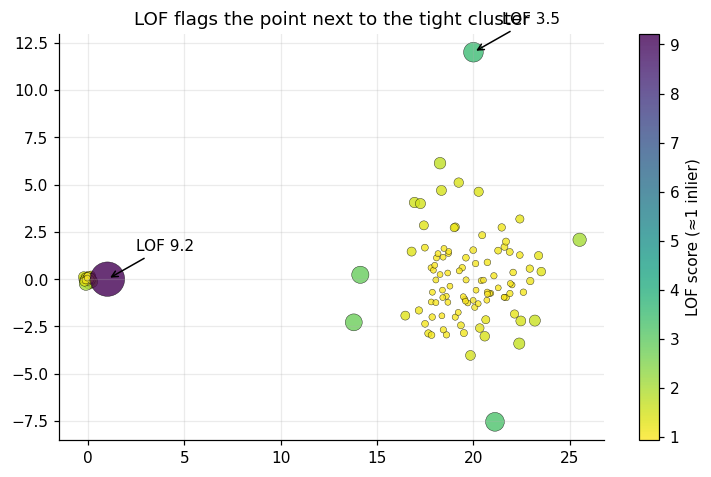

In [3]:
rng = np.random.default_rng(0)
tight = rng.normal(0, 0.1, size=(100, 2)); sparse = rng.normal([20, 0], 2.0, size=(100, 2))
X = np.vstack([tight, sparse, [[1.0, 0.0]], [[20.0, 12.0]]])
lof = LocalOutlierFactor(n_neighbors=10, contamination=0.02).fit(X)
score = -lof.negative_outlier_factor_
plt.figure(figsize=(8, 4.8))
plt.scatter(*X.T, s=15 + 60 * (score - 1).clip(0), c=score, cmap="viridis_r", alpha=0.8, edgecolor="k", linewidth=0.3); plt.colorbar(label="LOF score (≈1 inlier)")
for i in score.argsort()[-2:]: plt.annotate(f"LOF {score[i]:.1f}", X[i], (X[i][0] + 1.5, X[i][1] + 1.5), arrowprops=dict(arrowstyle="->"))
plt.title("LOF flags the point next to the tight cluster"); plt.show()

### 2. A global rule would miss it

Rank points by the distance to their k-th neighbour (the "isolated = far from others" idea). The local outlier near the tight cluster ranks far below many ordinary points of the sparse cluster, while LOF puts it first.

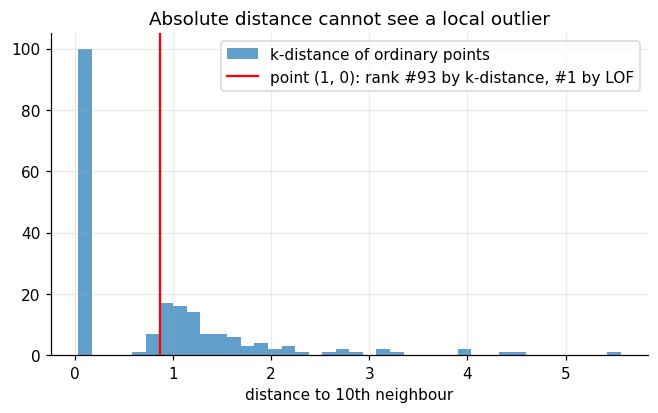

In [4]:
kd_rank = (lof.k_distance_ > lof.k_distance_[-2]).sum() + 1
lof_rank = (score > score[-2]).sum() + 1
plt.figure(figsize=(7, 3.8)); plt.hist(lof.k_distance_[:-2], bins=40, alpha=0.7, label="k-distance of ordinary points")
plt.axvline(lof.k_distance_[-2], color="r", label=f"point (1, 0): rank #{kd_rank} by k-distance, #{lof_rank} by LOF"); plt.xlabel("distance to 10th neighbour"); plt.legend(); plt.title("Absolute distance cannot see a local outlier"); plt.show()

### 3. The neighbourhood size `k`

Small `k` is noisy (every little fluctuation looks like an outlier); large `k` smooths over small groups of outliers (a group of anomalies bigger than `k` look like a normal cluster to each other). LOF of the planted local outlier as `k` changes:

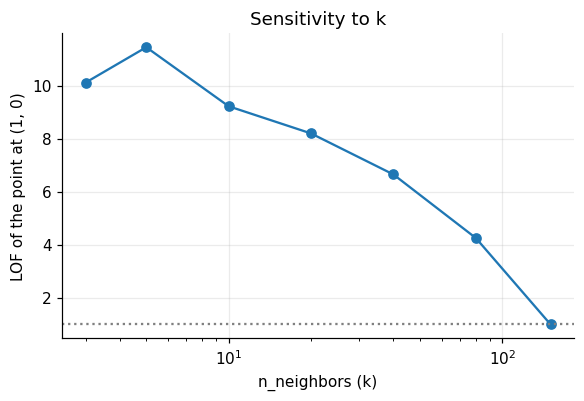

In [5]:
ks = [3, 5, 10, 20, 40, 80, 150]
vals = [-LocalOutlierFactor(n_neighbors=k).fit(X).negative_outlier_factor_[-2] for k in ks]
plt.figure(figsize=(6, 3.6)); plt.plot(ks, vals, "o-"); plt.axhline(1, color="gray", ls=":"); plt.xscale("log"); plt.xlabel("n_neighbors (k)"); plt.ylabel("LOF of the point at (1, 0)"); plt.title("Sensitivity to k"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.neighbors import LocalOutlierFactor as SklearnLOF

rng = np.random.default_rng(0)
X = np.vstack([rng.normal(0, 0.1, size=(150, 2)), rng.normal([20, 0], 2.0, size=(150, 2)), [[1.0, 0.0], [20.0, 12.0]]])
X_new = np.array([[0.0, 0.0], [20.0, 0.0], [1.0, 0.0], [10.0, 5.0]])

ours = LocalOutlierFactor(n_neighbors=15, contamination=0.02).fit(X)
theirs = SklearnLOF(n_neighbors=15, contamination=0.02).fit(X)
assert np.allclose(ours.negative_outlier_factor_, theirs.negative_outlier_factor_)
assert (ours.fit_predict(X) == theirs.fit_predict(X)).all()
print("LOF scores for all %d training points identical to sklearn" % len(X))

novel = SklearnLOF(n_neighbors=15, contamination=0.02, novelty=True).fit(X)
assert np.allclose(ours.score_samples(X_new), novel.score_samples(X_new))
assert (ours.predict(X_new) == novel.predict(X_new)).all()
print("scores for new points identical to sklearn (novelty=True): %s" % (-ours.score_samples(X_new)).round(2))

lof = -ours.negative_outlier_factor_
top = np.argsort(lof)[::-1][:2]
print("top-2 LOF: points %s with LOF %s (the two planted ones are %d and %d)" % (top, lof[top].round(2), len(X) - 2, len(X) - 1))
assert set(top) == {len(X) - 2, len(X) - 1}

# a global rule ("distance to the 15th neighbour") would rank the sparse cluster's members above the point at (1, 0)
print("(1,0) ranks #%d by k-distance, but #%d by LOF" % ((ours.k_distance_ > ours.k_distance_[-2]).sum() + 1, (lof > lof[-2]).sum() + 1))

LOF scores for all 302 training points identical to sklearn
scores for new points identical to sklearn (novelty=True): [1.02 0.99 8.1  4.15]
top-2 LOF: points [300 301] with LOF [8.84 4.56] (the two planted ones are 300 and 301)
(1,0) ranks #142 by k-distance, but #1 by LOF


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _two_densities(seed=0):
    """A very tight cluster, a very sparse one, and one point that is only moderately far from the tight one."""
    rng = np.random.default_rng(seed)
    tight = rng.normal(0, 0.1, size=(100, 2))
    sparse = rng.normal([20, 0], 2.0, size=(100, 2))
    local_outlier = np.array([[1.0, 0.0]])
    return np.vstack([tight, sparse, local_outlier])


def test_inliers_score_about_one():
    X = np.random.default_rng(0).normal(size=(300, 2))
    lof = -LocalOutlierFactor(n_neighbors=20).fit(X).negative_outlier_factor_
    assert 0.9 < np.median(lof) < 1.1


def test_catches_local_outlier_that_a_global_distance_rule_misses():
    X = _two_densities()
    i = len(X) - 1
    model = LocalOutlierFactor(n_neighbors=10).fit(X)
    lof = -model.negative_outlier_factor_
    assert lof.argmax() == i and lof[i] > 3
    # naive rule "distance to k-th neighbour": the sparse cluster's own members look MORE isolated
    assert (model.k_distance_ > model.k_distance_[i]).sum() > 20


def test_new_points_scored_against_training_set():
    X = _two_densities()
    model = LocalOutlierFactor(n_neighbors=10, contamination=0.02).fit(X)
    new = np.array([[0.0, 0.0], [20.0, 0.0], [1.0, 0.0], [10.0, 10.0]])
    assert model.predict(new).tolist() == [1, 1, -1, -1]


def test_fit_predict_flags_contamination_fraction():
    X = np.random.default_rng(1).normal(size=(200, 2))
    labels = LocalOutlierFactor(n_neighbors=15, contamination=0.05).fit_predict(X)
    assert abs((labels == -1).mean() - 0.05) < 0.01

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_inliers_score_about_one
PASS test_catches_local_outlier_that_a_global_distance_rule_misses
PASS test_new_points_scored_against_training_set
PASS test_fit_predict_flags_contamination_fraction

all 4 tests passed


## Takeaways

- **Use it** when density varies across the data (clusters of different tightness), or when you want a score that is interpretable (`≈1` normal, `≫1` outlier).
- **Method:** k-distance → reachability distance `max(k-dist(o), d(p, o))` → local reachability density `1/mean reach` → `LOF = mean(lrd of neighbours)/lrd(p)`.
- **Pitfalls:** one parameter `k` (try several), `O(n²)` brute force, distance loses meaning in high dimensions. Prefer `39_isolation_forest` for large or high-dimensional data.
- **Interview line:** *"LOF compares a point's local density with that of its neighbours; a ratio well above 1 means it is much sparser than its surroundings."*